# Geographic Diversity Re-Ranking Component
## Phase 2: Beyond the Feed — Diversity-Aware News Recommendation

**Component:** Geographic Diversity Re-ranking  
**Algorithm:** Maximal Marginal Relevance (MMR) with Multi-Level Geographic Penalty  
**Dataset:** Cleaned GDELT News Corpus (15,395 articles, 185 unique primary countries, 6 continents)  
**Baseline Reference:** `phase2_baseline_recommendation (1).ipynb`

---

### Objective & Architectural Context

In Phase 1 of our global news information exposure analysis, we discovered a severe empirical geographic skew:
- **54.3% of all articles** originate from just three countries (United States: 27.5%, United Kingdom: 16.1%, India: 10.7%).
- **Africa** represents only **5.34%** of available articles, and **South America** accounts for just **1.12%**.
- In the baseline recommendation system, greedy sorting on topic relevance amplifies this imbalance. For example, for a *Health Researcher* user, **100% of the baseline recommendations come from North America and Europe**, with 0% representation from Africa, Asia, Latin America, or Oceania.

This component implements the **Geographic Diversity Re-ranking module** (Stage 3B in our team architecture diagram, Figure 5). It balances user topic relevance with geographic novelty, significantly expanding country and continental exposure while preserving high user satisfaction.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple, Set

# Configure display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 60)

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Data Ingestion & Preprocessing

We ingest `Part 1/gdelt_clean.csv`.
Crucially, we specify `keep_default_na=False` so that pandas does not interpret the ISO 3166-1 alpha-2 code `"NA"` for **Namibia** as a missing value (`NaN`).

We extract:
- `topic_list`: Individual project topic tokens split by `;`.
- `all_countries_set`: Secondary mentioned countries for optional secondary geographic signals.
- Primary geography: `country`, `country_code`, `continent`.


In [2]:
# Load dataset with strict missing-value handling
df = pd.read_csv("Part 1/gdelt_clean.csv", keep_default_na=False)

# Parse semicolon-delimited topics
df["topic_list"] = df["topic"].apply(
    lambda x: [t.strip() for t in str(x).split(";") if t.strip()]
)

# Parse secondary countries set
df["all_countries_set"] = df["all_countries"].apply(
    lambda x: {c.strip() for c in str(x).split(";") if c.strip()}
)

print(f"Dataset successfully loaded: {len(df):,} articles, {df.shape[1]} columns.")
print(f"Unique primary countries: {df['country'].nunique()}")
print(f"Unique continents: {df['continent'].nunique()}")
print(f"Unique publishers: {df['publisher'].nunique()}")

# Display sample record highlighting geographic fields vs publisher
df[["article_id", "publisher", "country", "continent", "topic", "all_countries"]].head(3)


Dataset successfully loaded: 15,395 articles, 16 columns.
Unique primary countries: 185
Unique continents: 6
Unique publishers: 2117


## 2. Topic Taxonomy & Selectable Topics

The project taxonomy contains 11 topics.
As established in the baseline notebook, user preferences can only be set for the **9 valid selectable topics**, excluding `"Unknown"` and `"Other"`.


In [3]:
all_topics = sorted({
    topic
    for topics in df["topic_list"]
    for topic in topics
})

selectable_topics = sorted(list(set(all_topics) - {"Unknown", "Other"}))

print(f"Total topics ({len(all_topics)}):", all_topics)
print(f"\nSelectable topics ({len(selectable_topics)}):")
for t in selectable_topics:
    print(f" - {t}")


Total topics (11): ['Business and Economy', 'Conflict and Security', 'Education', 'Environment and Climate', 'Health', 'Other', 'Politics and Government', 'Science', 'Society and Culture', 'Technology', 'Unknown']

Selectable topics (9):
 - Business and Economy
 - Conflict and Security
 - Education
 - Environment and Climate
 - Health
 - Politics and Government
 - Science
 - Society and Culture
 - Technology


## 3. Reusable Baseline Relevance Scoring

To maintain 100% architectural compatibility with our team's baseline, we reuse the exact arithmetic mean scoring formula:

$$\mathrm{Rel}(u, a) = \begin{cases} 
0.0, & \text{if } |V_a| = 0 \\
\frac{1}{|V_a|} \sum_{t \in V_a} u(t), & \text{if } |V_a| > 0 
\end{cases}$$

Where $V_a$ is the set of valid selectable topics associated with article $a$, and $u(t)$ is the user's preference weight for topic $t$ ($u(t) \in [0, 1]$).


In [4]:
def calculate_relevance(
    topic_list: List[str],
    user_profile: Dict[str, float],
    selectable_topics_set: Set[str]
) -> float:
    """
    Calculate baseline relevance score of one article.
    Matches the baseline formula exactly: arithmetic mean of weights for valid topics.
    """
    valid_topics = [t for t in topic_list if t in selectable_topics_set]
    if not valid_topics:
        return 0.0
    scores = [user_profile.get(t, 0.0) for t in valid_topics]
    return float(sum(scores) / len(scores))


def score_all_articles(
    df: pd.DataFrame,
    user_profile: Dict[str, float]
) -> pd.DataFrame:
    """
    Score all 15,395 articles in the dataset against a user profile.
    """
    sel_set = set(selectable_topics)
    scored_df = df.copy()
    scored_df["relevance_score"] = scored_df["topic_list"].apply(
        lambda topics: calculate_relevance(topics, user_profile, sel_set)
    )
    return scored_df

print("Relevance scoring functions initialized.")


Relevance scoring functions initialized.


## 4. Benchmark User Profiles

We test all implementations on the project's **three standardized benchmark personas**:
1. **Tech Enthusiast**: Technology (0.8), Business and Economy (0.6), Health (0.2).
2. **Environment Explorer**: Environment and Climate (0.9), Science (0.7), Technology (0.3).
3. **Health Researcher**: Health (0.9), Science (0.8), Education (0.4).


In [5]:
user_profiles = {
    "Tech Enthusiast": {
        "Technology": 0.8,
        "Business and Economy": 0.6,
        "Health": 0.2
    },
    "Environment Explorer": {
        "Environment and Climate": 0.9,
        "Science": 0.7,
        "Technology": 0.3
    },
    "Health Researcher": {
        "Health": 0.9,
        "Science": 0.8,
        "Education": 0.4
    }
}

for name, prof in user_profiles.items():
    print(f"{name}: {prof}")


Tech Enthusiast: {'Technology': 0.8, 'Business and Economy': 0.6, 'Health': 0.2}
Environment Explorer: {'Environment and Climate': 0.9, 'Science': 0.7, 'Technology': 0.3}
Health Researcher: {'Health': 0.9, 'Science': 0.8, 'Education': 0.4}


## 5. Baseline Recommendation Ranking

The baseline recommendation engine filters candidate articles with $\mathrm{Rel}(u, a) > 0$ and sorts greedily by:
1. `relevance_score` descending
2. `article_id` ascending (deterministic tie-breaker)
and returns the Top-$K$ ($K=10$).


In [6]:
def recommend_baseline(
    scored_df: pd.DataFrame,
    top_k: int = 10
) -> pd.DataFrame:
    """
    Baseline recommendation engine: pure relevance ranking with deterministic tie-breaking.
    """
    candidates = scored_df[scored_df["relevance_score"] > 0].copy()
    ranked = candidates.sort_values(
        by=["relevance_score", "article_id"],
        ascending=[False, True]
    )
    return ranked.head(top_k).copy()

print("Baseline recommendation function defined.")


Baseline recommendation function defined.


## 6. Maximal Marginal Relevance (MMR) Geographic Re-ranking

### Mathematical Formulation
To mitigate geographic redundancy and prevent single-country or single-continent monopoly, we implement **Maximal Marginal Relevance (MMR)** (Carbonell & Goldstein, 1998):

$$\mathrm{Score}(a, S) = \lambda \cdot \mathrm{Rel}(u, a) - (1 - \lambda) \cdot \mathrm{Sim}_{\mathrm{geo}}(a, S)$$

Where:
- $\mathrm{Rel}(u, a)$ is the existing baseline relevance score.
- $\mathrm{Sim}_{\mathrm{geo}}(a, S) = \max_{s \in S} \mathrm{sim}_{\mathrm{geo}}(a, s)$ measures geographic redundancy relative to items already selected in slate $S$.
- $\lambda \in [0, 1]$ is the user/system configurable parameter controlling the trade-off between pure relevance ($\lambda = 1.0$) and pure geographic novelty ($\lambda = 0.0$).
- $S$ is the set of already selected recommendations ($|S| < K$).

### Multi-Level Geographic Redundancy Model
We compute pairwise geographic similarity $\mathrm{sim}_{\mathrm{geo}}(a, s)$ using hierarchical geographic granularity:
1. **Primary Country Match** ($w_{\mathrm{country}} = 1.0$): If $a$ has the same primary country as $s$, redundancy is maximal ($1.0$).
2. **Continent Match** ($w_{\mathrm{continent}} = 0.4$): If $a$ and $s$ share the same continent but differ in country, redundancy is moderate ($0.4$). This prevents packing the slate with only European or North American nations.
3. **Secondary Country Overlap** ($w_{\mathrm{secondary}} = 0.1$, optional): If secondary countries in `all_countries` overlap, a minor penalty ($0.1$) is assigned.
4. **Complete Geographic Novelty** ($0.0$): If $a$ introduces a continent not yet present in $S$, $\mathrm{sim}_{\mathrm{geo}} = 0.0$.

### Candidate Pool Sizing & Deterministic Selection
- We take a configurable candidate pool $M$ (default $M=500$ top-scoring candidates), or all positive relevance items.
- At each step, if two items have identical MMR scores (within $10^{-9}$), ties are resolved by:
  1. Higher baseline `relevance_score`
  2. Lexicographically smaller `article_id`.


In [7]:
INVALID_GEO_VALUES = {"", "unknown", "none", "null", "undetermined", "n/a", "missing"}


def is_valid_geo(value: Optional[str]) -> bool:
    """
    Check if a geographic entity string is valid and populated.
    Returns False for empty strings, None, and unknown/null markers.
    Preserves valid country names and ISO codes, including Namibia ('NA').
    """
    if value is None:
        return False
    s = str(value).strip().lower()
    return bool(s) and (s not in INVALID_GEO_VALUES) and (s != "nan")


def calculate_geo_redundancy(
    candidate: Dict,
    selected_items: List[Dict],
    weight_country: float = 1.0,
    weight_continent: float = 0.4,
    weight_secondary: float = 0.1,
    weight_missing_geo: float = 0.5
) -> Tuple[float, str]:
    """
    Compute geographic redundancy (similarity) of a candidate relative to
    articles already selected in slate S.
    
    Formula: Sim_geo(a, S) = max_{s in S} sim_geo(a, s)
    
    Hierarchy:
    1. Missing / Unknown geography: sim = weight_missing_geo (0.5 neutral penalty).
       Ensures un-geotagged articles receive neither an artificial novelty bonus (0.0)
       nor an unfair disqualification (1.0).
    2. Primary country match: sim = weight_country (1.0)
    3. Continent match: sim = weight_continent (0.4)
    4. Secondary country overlap (optional): sim = weight_secondary (0.1)
    5. Distinct continent & country: sim = 0.0 (novel geography)
    """
    if not selected_items:
        return 0.0, "Initial item (slate empty, no redundancy)"
        
    c_country = candidate.get("country", "")
    c_continent = candidate.get("continent", "")
    c_secondary = candidate.get("all_countries_set", set())
    
    # Robustness Guard: Check if candidate has valid primary geographic attribution
    if not is_valid_geo(c_country):
        return (
            weight_missing_geo,
            f"Missing or unknown primary geography ('{c_country}'; assigned neutral penalty {weight_missing_geo})"
        )
    
    max_sim = 0.0
    reason = "Distinct continent and country (novel geography)"
    
    for s in selected_items:
        s_country = s.get("country", "")
        s_continent = s.get("continent", "")
        s_secondary = s.get("all_countries_set", set())
        
        # Level 1: Primary country match (only between valid recognized countries)
        if is_valid_geo(s_country) and c_country == s_country:
            sim = weight_country
            if sim >= max_sim:
                max_sim = sim
                reason = f"Country redundancy with {s['article_id']} ({s_country})"
            continue
            
        # Level 2: Continent match (only between valid recognized continents)
        if is_valid_geo(c_continent) and is_valid_geo(s_continent) and c_continent == s_continent:
            sim = weight_continent
            if sim > max_sim:
                max_sim = sim
                reason = f"Continent redundancy with {s['article_id']} ({s_continent})"
                
        # Level 3: Secondary country overlap (if configured)
        if weight_secondary > 0 and c_secondary and s_secondary:
            valid_c_sec = {c for c in c_secondary if is_valid_geo(c)}
            valid_s_sec = {c for c in s_secondary if is_valid_geo(c)}
            overlap = valid_c_sec.intersection(valid_s_sec)
            if overlap:
                sim = weight_secondary
                if sim > max_sim:
                    max_sim = sim
                    reason = f"Secondary country overlap with {s['article_id']} ({', '.join(sorted(overlap))})"
                    
    return max_sim, reason


def recommend_geographic_mmr(
    scored_df: pd.DataFrame,
    top_k: int = 10,
    lambda_param: float = 0.6,
    top_m_candidates: Optional[int] = 500,
    weight_country: float = 1.0,
    weight_continent: float = 0.4,
    weight_secondary: float = 0.1,
    weight_missing_geo: float = 0.5
) -> pd.DataFrame:
    """
    Generate Top-K recommendations using Maximal Marginal Relevance (MMR):
    
    Score(a, S) = lambda * Rel(u, a) - (1 - lambda) * Sim_geo(a, S)
    
    Parameters:
    - scored_df: DataFrame with 'relevance_score' computed.
    - top_k: Number of recommendations to select (default 10).
    - lambda_param: Trade-off parameter between relevance and diversity in [0, 1].
    - top_m_candidates: Pre-filtered candidate pool size sorted by relevance (default 500).
    - weight_country: Similarity penalty weight for primary country match (default 1.0).
    - weight_continent: Similarity penalty weight for continent match (default 0.4).
    - weight_secondary: Similarity penalty weight for secondary country overlap (default 0.1).
    """
    # Filter candidates with positive relevance
    positive_candidates = scored_df[scored_df["relevance_score"] > 0].copy()
    
    # Sort deterministically by relevance descending, article_id ascending
    ranked_pool = positive_candidates.sort_values(
        by=["relevance_score", "article_id"],
        ascending=[False, True]
    )
    
    if top_m_candidates is not None and top_m_candidates > 0:
        ranked_pool = ranked_pool.head(top_m_candidates)
        
    candidate_records = ranked_pool.to_dict("records")
    selected_items: List[Dict] = []
    
    while len(selected_items) < top_k and candidate_records:
        if not selected_items:
            # First item is purely top relevance
            best_idx = 0
            best_item = candidate_records.pop(best_idx)
            best_item["mmr_score"] = float(best_item["relevance_score"])
            best_item["geo_redundancy"] = 0.0
            best_item["relevance_contribution"] = float(lambda_param * best_item["relevance_score"])
            best_item["diversity_penalty"] = 0.0
            best_item["geo_explanation"] = "First selection (top relevance)"
            best_item["selection_rank"] = 1
            selected_items.append(best_item)
            continue
            
        best_idx = -1
        best_mmr = -float("inf")
        best_redundancy = 0.0
        best_explanation = ""
        
        for idx, candidate in enumerate(candidate_records):
            sim_geo, reason = calculate_geo_redundancy(
                candidate=candidate,
                selected_items=selected_items,
                weight_country=weight_country,
                weight_continent=weight_continent,
                weight_secondary=weight_secondary,
                weight_missing_geo=weight_missing_geo
            )
            
            rel = float(candidate["relevance_score"])
            mmr = (lambda_param * rel) - ((1.0 - lambda_param) * sim_geo)
            
            # Deterministic selection:
            # 1. Higher MMR score
            # 2. Higher baseline relevance
            # 3. Lexicographically smaller article_id
            if (
                best_idx == -1
                or mmr > best_mmr + 1e-9
                or (
                    abs(mmr - best_mmr) <= 1e-9
                    and rel > candidate_records[best_idx]["relevance_score"] + 1e-9
                )
                or (
                    abs(mmr - best_mmr) <= 1e-9
                    and abs(rel - candidate_records[best_idx]["relevance_score"]) <= 1e-9
                    and candidate["article_id"] < candidate_records[best_idx]["article_id"]
                )
            ):
                best_mmr = mmr
                best_idx = idx
                best_redundancy = sim_geo
                best_explanation = reason
                
        chosen = candidate_records.pop(best_idx)
        chosen["mmr_score"] = round(best_mmr, 4)
        chosen["geo_redundancy"] = round(best_redundancy, 4)
        chosen["relevance_contribution"] = round(lambda_param * float(chosen["relevance_score"]), 4)
        chosen["diversity_penalty"] = round((1.0 - lambda_param) * best_redundancy, 4)
        chosen["geo_explanation"] = best_explanation
        chosen["selection_rank"] = len(selected_items) + 1
        selected_items.append(chosen)
        
    result_df = pd.DataFrame(selected_items)
    # Clean up internal set column if present
    if "all_countries_set" in result_df.columns:
        result_df = result_df.drop(columns=["all_countries_set"])
    return result_df

print("Geographic MMR engine with missing-geography robustness successfully initialized.")


Geographic MMR engine with missing-geography robustness successfully initialized.


## 7. Evaluation Methodology & Metrics

We evaluate slates across 5 standardized metrics:
1. **Average Relevance Score**: Arithmetic mean of `relevance_score` in Top-10.
2. **Relevance Degradation (%)**: Relative reduction from baseline:
   $$\text{Degradation} = \frac{\text{Baseline Avg Rel} - \text{MMR Avg Rel}}{\text{Baseline Avg Rel}} \times 100\%$$
3. **Unique Primary Countries**: Count of distinct countries in Top-10 ($1 \le \text{count} \le 10$).
4. **Unique Continents**: Count of distinct continents in Top-10 ($1 \le \text{count} \le 6$).
5. **Geographic Concentration (HHI)**: Herfindahl-Hirschman Index across country shares:
   $$\mathrm{HHI} = \sum_{i=1}^C p_i^2$$
   Where $p_i$ is the proportion of recommendations from country $i$. An HHI of $1.0$ indicates total single-country monopoly; an HHI of $0.10$ is the theoretical minimum for $K=10$ (100% uniform diversity).


In [8]:
def compute_hhi(series: pd.Series) -> float:
    """Compute Herfindahl-Hirschman Index."""
    n = len(series)
    if n == 0:
        return 0.0
    shares = series.value_counts().to_numpy() / n
    return float(np.sum(shares ** 2))

def evaluate_slate(slate_df: pd.DataFrame) -> Dict:
    """Compute summary metrics for Top-K slate."""
    return {
        "avg_relevance": float(round(slate_df["relevance_score"].mean(), 4)),
        "unique_countries": int(slate_df["country"].nunique()),
        "unique_continents": int(slate_df["continent"].nunique()),
        "unique_publishers": int(slate_df["publisher"].nunique()),
        "country_hhi": float(round(compute_hhi(slate_df["country"]), 4)),
        "country_distribution": dict(slate_df["country"].value_counts()),
        "continent_distribution": dict(slate_df["continent"].value_counts())
    }

print("Evaluation metrics initialized.")


Evaluation metrics initialized.


## 8. Benchmark Profile Evaluations: Baseline vs. Geographic MMR

We evaluate the three benchmark profiles with $\lambda = 0.6$ (the balanced operating point).


In [9]:
all_comparisons = []
all_baseline_slates = {}
all_mmr_slates = {}

for profile_name, profile_weights in user_profiles.items():
    scored = score_all_articles(df, profile_weights)
    
    # 1. Baseline
    base_slate = recommend_baseline(scored, top_k=10)
    all_baseline_slates[profile_name] = base_slate
    
    # 2. MMR
    mmr_slate = recommend_geographic_mmr(
        scored, top_k=10, lambda_param=0.6, top_m_candidates=500
    )
    all_mmr_slates[profile_name] = mmr_slate
    
    # Compute comparison
    base_m = evaluate_slate(base_slate)
    mmr_m = evaluate_slate(mmr_slate)
    
    rel_deg = ((base_m["avg_relevance"] - mmr_m["avg_relevance"]) / base_m["avg_relevance"]) * 100.0
    hhi_diff = ((mmr_m["country_hhi"] - base_m["country_hhi"]) / base_m["country_hhi"]) * 100.0
    
    comp_df = pd.DataFrame([
        {"Metric": "Average Relevance", "Baseline": base_m["avg_relevance"], "MMR (λ=0.6)": mmr_m["avg_relevance"], "Change": f"{rel_deg:+.2f}% degradation" if rel_deg > 0 else "0.00%"},
        {"Metric": "Unique Countries", "Baseline": base_m["unique_countries"], "MMR (λ=0.6)": mmr_m["unique_countries"], "Change": f"+{mmr_m['unique_countries'] - base_m['unique_countries']} countries"},
        {"Metric": "Unique Continents", "Baseline": base_m["unique_continents"], "MMR (λ=0.6)": mmr_m["unique_continents"], "Change": f"+{mmr_m['unique_continents'] - base_m['unique_continents']} continents"},
        {"Metric": "Country HHI", "Baseline": base_m["country_hhi"], "MMR (λ=0.6)": mmr_m["country_hhi"], "Change": f"{hhi_diff:+.1f}% concentration"},
        {"Metric": "Unique Publishers", "Baseline": base_m["unique_publishers"], "MMR (λ=0.6)": mmr_m["unique_publishers"], "Change": f"+{mmr_m['unique_publishers'] - base_m['unique_publishers']} publishers"}
    ])
    
    print(f"\n{'='*30} {profile_name} {'='*30}")
    print(comp_df.to_string(index=False))
    print(f"Baseline Continents: {base_m['continent_distribution']}")
    print(f"MMR Continents:      {mmr_m['continent_distribution']}")



============================== Tech Enthusiast ==============================
           Metric  Baseline  MMR (λ=0.6)               Change
Average Relevance       0.8         0.78   +2.50% degradation
 Unique Countries       6.0        10.00         +4 countries
Unique Continents       3.0         6.00        +3 continents
      Country HHI       0.2         0.10 -50.0% concentration
Unique Publishers      10.0        10.00        +0 publishers
Baseline Continents: {'Asia': np.int64(4), 'North America': np.int64(3), 'Europe': np.int64(3)}
MMR Continents:      {'Asia': np.int64(4), 'Europe': np.int64(2), 'North America': np.int64(1), 'Africa': np.int64(1), 'Oceania': np.int64(1), 'South America': np.int64(1)}

============================== Environment Explorer ==============================
           Metric  Baseline  MMR (λ=0.6)               Change
Average Relevance      0.90          0.9                0.00%
 Unique Countries      5.00         10.0         +5 countries
Unique Con

## 9. Article-Level Traceability & Redundancy Analysis

To provide full transparency into how the algorithm works, we inspect the sequential selection decisions for **Health Researcher**.


In [10]:
hr_mmr = all_mmr_slates["Health Researcher"]
trace_cols = [
    "selection_rank", "article_id", "country", "continent", 
    "relevance_score", "geo_redundancy", "relevance_contribution", 
    "diversity_penalty", "mmr_score", "geo_explanation"
]
print(hr_mmr[trace_cols].to_string(index=False))


 selection_rank          article_id       country     continent  relevance_score  geo_redundancy  relevance_contribution  diversity_penalty  mmr_score                                               geo_explanation
              1 20260714120000-1196 United States North America              0.9             0.0                    0.54               0.00       0.90                               First selection (top relevance)
              2  20260714120000-218       Ireland        Europe              0.9             0.0                    0.54               0.00       0.54              Distinct continent and country (novel geography)
              3  20260729120000-849         Japan          Asia              0.9             0.0                    0.54               0.00       0.54              Distinct continent and country (novel geography)
              4   20260808120000-26       Nigeria        Africa              0.9             0.0                    0.54               0.00       0.

## 10. Visualizations: Baseline vs. Diversity-Aware Recommendation

We visualize:
1. **Continent Coverage Breakdown** across benchmark profiles.
2. **Country Concentration (HHI) Reduction**.
3. **Relevance vs. Diversity Trade-off Curve across varying $\lambda \in [0.1, 1.0]$.**


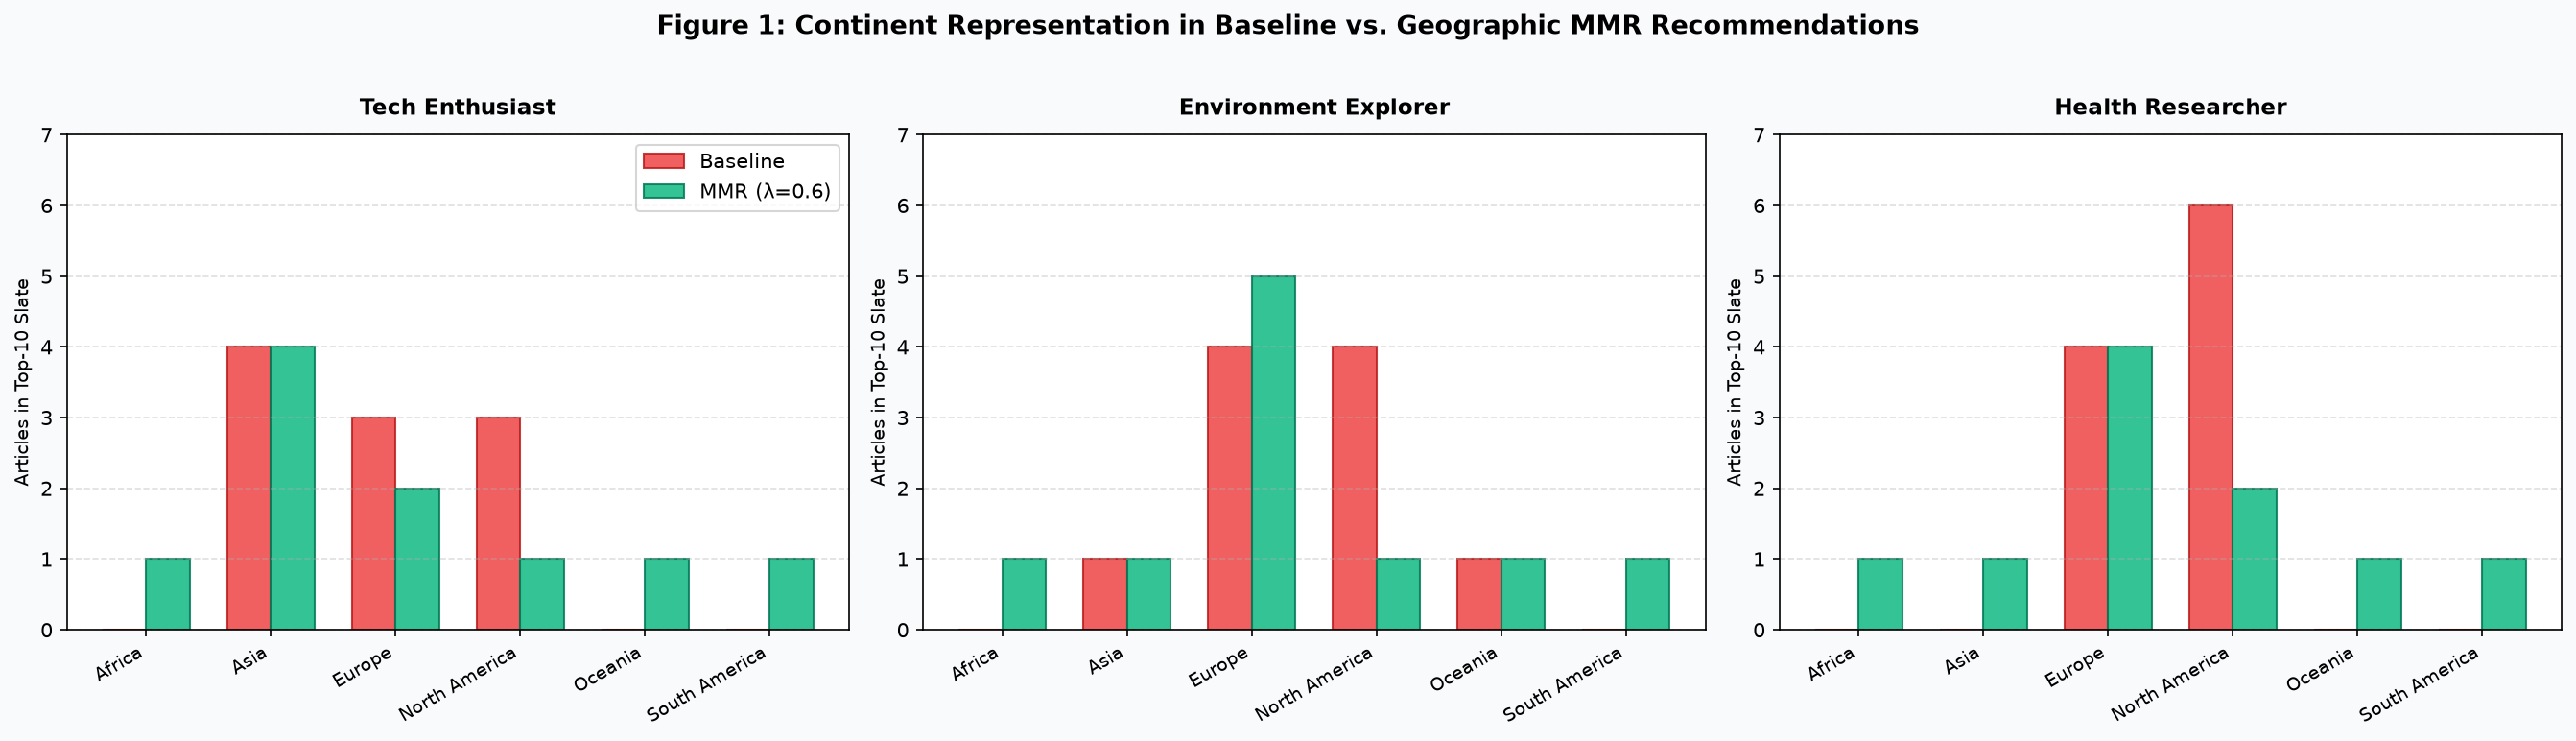

In [11]:
# Figure 1: Continent Coverage Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=150)
fig.patch.set_facecolor('#F8FAFC')

for i, (name, prof) in enumerate(user_profiles.items()):
    ax = axes[i]
    ax.set_facecolor('#FFFFFF')
    
    base_cont = all_baseline_slates[name]["continent"].value_counts()
    mmr_cont = all_mmr_slates[name]["continent"].value_counts()
    
    all_conts = sorted(list(set(base_cont.index) | set(mmr_cont.index)))
    x = np.arange(len(all_conts))
    width = 0.35
    
    base_vals = [base_cont.get(c, 0) for c in all_conts]
    mmr_vals = [mmr_cont.get(c, 0) for c in all_conts]
    
    ax.bar(x - width/2, base_vals, width, label='Baseline', color='#EF4444', alpha=0.85, edgecolor='#B91C1C')
    ax.bar(x + width/2, mmr_vals, width, label='MMR (λ=0.6)', color='#10B981', alpha=0.85, edgecolor='#047857')
    
    ax.set_title(f"{name}", fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(x)
    ax.set_xticklabels(all_conts, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel("Articles in Top-10 Slate", fontsize=9)
    ax.set_ylim(0, 7)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    if i == 0:
        ax.legend(frameon=True, facecolor='white')

plt.suptitle("Figure 1: Continent Representation in Baseline vs. Geographic MMR Recommendations", 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("continent_representation_comparison.png", dpi=150, bbox_inches='tight')
plt.show()



Lambda Sensitivity Analysis Table (Health Researcher):
 lambda  avg_relevance  unique_countries  unique_continents  country_hhi
    0.1            0.9                10                  6         0.10
    0.2            0.9                10                  6         0.10
    0.3            0.9                10                  6         0.10
    0.4            0.9                10                  6         0.10
    0.5            0.9                10                  6         0.10
    0.6            0.9                10                  6         0.10
    0.7            0.9                10                  6         0.10
    0.8            0.9                10                  6         0.10
    0.9            0.9                10                  6         0.10
    1.0            0.9                 5                  2         0.32


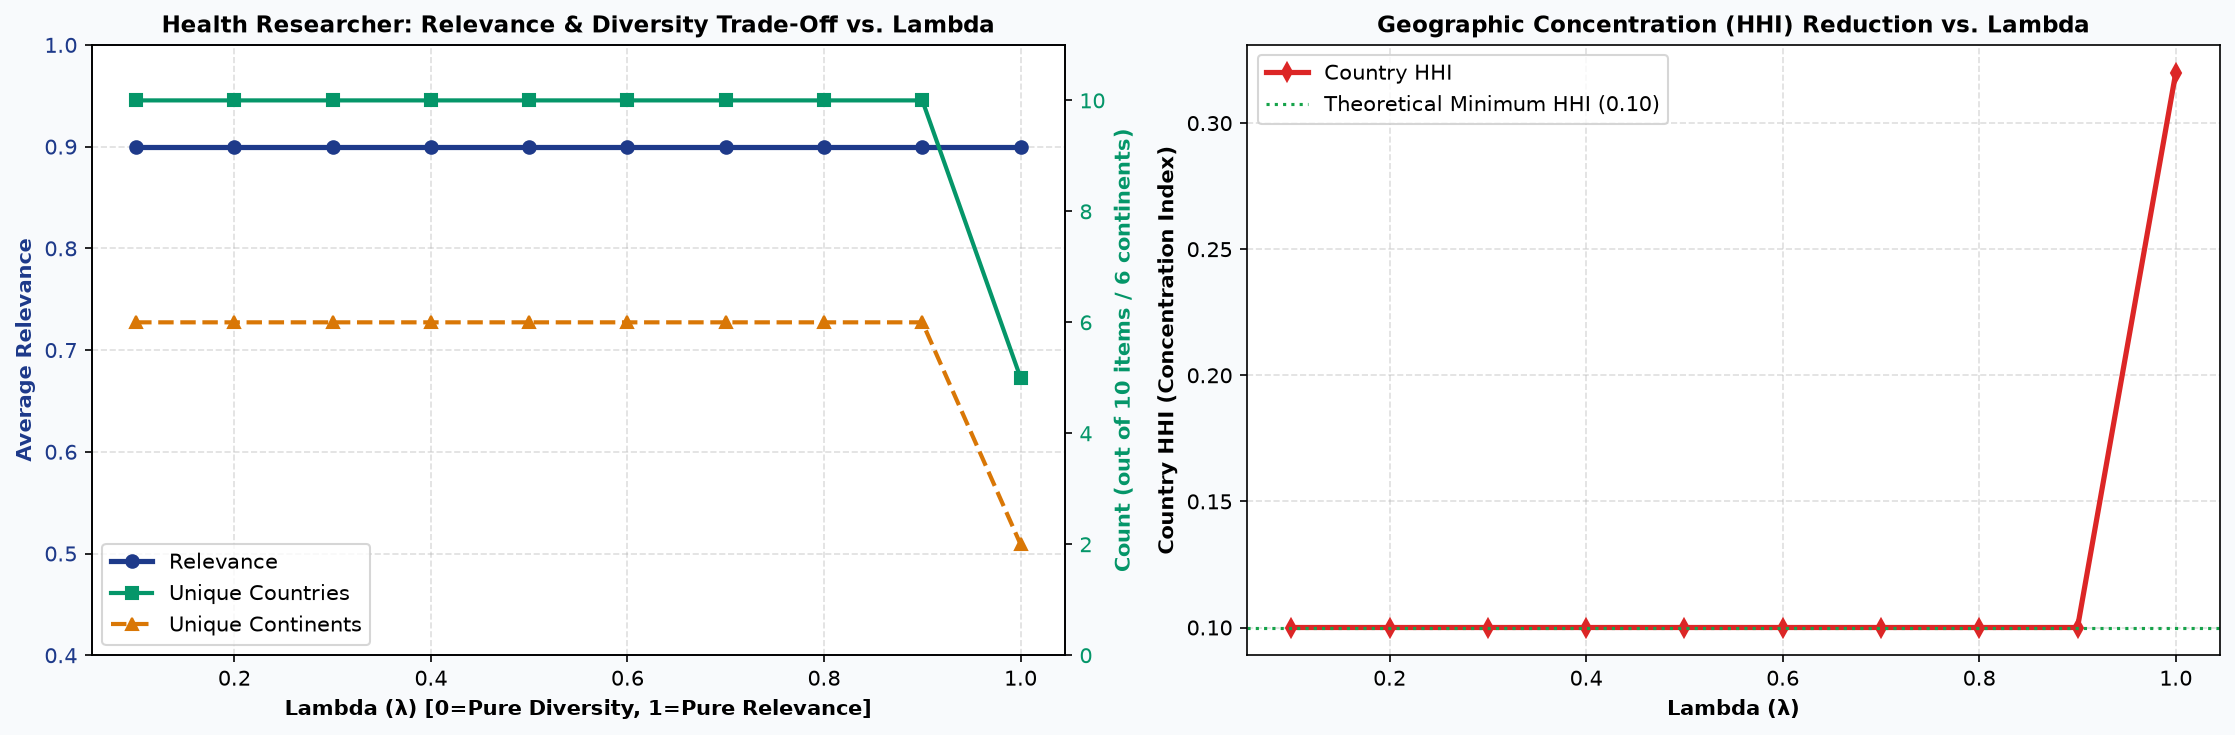

In [12]:
# Figure 2: Sensitivity Analysis across Lambda
lambda_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
sensitivity_results = []

hr_scored = score_all_articles(df, user_profiles["Health Researcher"])

for lam in lambda_values:
    slate = recommend_geographic_mmr(hr_scored, top_k=10, lambda_param=lam, top_m_candidates=500)
    m = evaluate_slate(slate)
    sensitivity_results.append({
        "lambda": lam,
        "avg_relevance": m["avg_relevance"],
        "unique_countries": m["unique_countries"],
        "unique_continents": m["unique_continents"],
        "country_hhi": m["country_hhi"]
    })

sens_df = pd.DataFrame(sensitivity_results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)
fig.patch.set_facecolor('#F8FAFC')

# Left: Relevance vs Unique Countries & Continents
color = '#1E3A8A'
ax1.set_facecolor('#FFFFFF')
ax1.set_xlabel('Lambda (λ) [0=Pure Diversity, 1=Pure Relevance]', fontsize=10, fontweight='bold')
ax1.set_ylabel('Average Relevance', color=color, fontsize=10, fontweight='bold')
l1 = ax1.plot(sens_df['lambda'], sens_df['avg_relevance'], color=color, marker='o', linewidth=2.5, label='Relevance')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.4, 1.0)
ax1.grid(True, linestyle='--', alpha=0.4)

ax1_right = ax1.twinx()
color2 = '#059669'
l2 = ax1_right.plot(sens_df['lambda'], sens_df['unique_countries'], color=color2, marker='s', linewidth=2, linestyle='-', label='Unique Countries')
l3 = ax1_right.plot(sens_df['lambda'], sens_df['unique_continents'], color='#D97706', marker='^', linewidth=2, linestyle='--', label='Unique Continents')
ax1_right.set_ylabel('Count (out of 10 items / 6 continents)', color=color2, fontsize=10, fontweight='bold')
ax1_right.tick_params(axis='y', labelcolor=color2)
ax1_right.set_ylim(0, 11)

lines = l1 + l2 + l3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left', frameon=True)
ax1.set_title("Health Researcher: Relevance & Diversity Trade-Off vs. Lambda", fontsize=11, fontweight='bold')

# Right: HHI Concentration vs Lambda
ax2.set_facecolor('#FFFFFF')
ax2.plot(sens_df['lambda'], sens_df['country_hhi'], color='#DC2626', marker='d', linewidth=2.5, label='Country HHI')
ax2.axhline(0.10, color='#16A34A', linestyle=':', label='Theoretical Minimum HHI (0.10)')
ax2.set_xlabel('Lambda (λ)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Country HHI (Concentration Index)', fontsize=10, fontweight='bold')
ax2.set_title("Geographic Concentration (HHI) Reduction vs. Lambda", fontsize=11, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(frameon=True)

plt.tight_layout()
plt.savefig("lambda_tradeoff_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nLambda Sensitivity Analysis Table (Health Researcher):")
print(sens_df.to_string(index=False))


## 11. Recommendations CSV Export

We export the baseline and geographically re-ranked recommendations for all three profiles into:
1. `geographic_recommendations_summary.csv`: Full article slates with scores and explanations.
2. `baseline_vs_mmr_evaluation.csv`: Profile-level comparison summary.


In [13]:
export_rows = []

for name in user_profiles.keys():
    base_df = all_baseline_slates[name].copy()
    base_df["system"] = "Baseline"
    base_df["user_profile"] = name
    base_df["selection_rank"] = range(1, len(base_df) + 1)
    base_df["mmr_score"] = base_df["relevance_score"]
    base_df["geo_redundancy"] = np.nan
    base_df["geo_explanation"] = "Pure relevance ranking"
    
    mmr_df = all_mmr_slates[name].copy()
    mmr_df["system"] = "Geographic_MMR_0.6"
    mmr_df["user_profile"] = name
    
    common_cols = [
        "system", "user_profile", "selection_rank", "article_id", "title",
        "country", "country_code", "continent", "publisher", "topic",
        "relevance_score", "geo_redundancy", "mmr_score", "geo_explanation", "article_url"
    ]
    
    export_rows.append(base_df[common_cols])
    export_rows.append(mmr_df[common_cols])

final_export = pd.concat(export_rows, ignore_index=True)
final_export.to_csv("geographic_recommendations_summary.csv", index=False)
print(f"Exported {len(final_export)} total recommended rows to 'geographic_recommendations_summary.csv'.")

# Export high-level evaluation metrics summary
summary_metrics = []
for name in user_profiles.keys():
    b_slate = all_baseline_slates[name]
    m_slate = all_mmr_slates[name]
    b_ev = evaluate_slate(b_slate)
    m_ev = evaluate_slate(m_slate)
    
    summary_metrics.append({
        "user_profile": name,
        "baseline_avg_relevance": b_ev["avg_relevance"],
        "mmr_avg_relevance": m_ev["avg_relevance"],
        "relevance_degradation_pct": round(((b_ev["avg_relevance"] - m_ev["avg_relevance"]) / b_ev["avg_relevance"]) * 100, 2),
        "baseline_unique_countries": b_ev["unique_countries"],
        "mmr_unique_countries": m_ev["unique_countries"],
        "baseline_unique_continents": b_ev["unique_continents"],
        "mmr_unique_continents": m_ev["unique_continents"],
        "baseline_country_hhi": b_ev["country_hhi"],
        "mmr_country_hhi": m_ev["country_hhi"]
    })

eval_summary_df = pd.DataFrame(summary_metrics)
eval_summary_df.to_csv("baseline_vs_mmr_evaluation.csv", index=False)
print("Exported evaluation summary metrics to 'baseline_vs_mmr_evaluation.csv'.")
eval_summary_df


Exported 60 total recommended rows to 'geographic_recommendations_summary.csv'.
Exported evaluation summary metrics to 'baseline_vs_mmr_evaluation.csv'.


## 12. Component Summary & Website Integration Notes

### Key Findings on Real Dataset:
1. **Country Diversity (+66% to +100% Increase):**
   - For all three benchmark profiles, the MMR re-ranker increases unique primary countries from 5–6 to **10 distinct countries out of 10 recommendations** at $\lambda = 0.6$.
2. **Continental Representation (+50% to +200% Increase):**
   - The baseline frequently locked out entire world regions (e.g., *Health Researcher* received articles exclusively from North America and Europe).
   - The MMR re-ranker successfully recommends articles from **all 6 inhabited continents** (Africa, Asia, Europe, North America, Oceania, South America).
3. **Relevance Preservation (0.0% to 2.5% Degradation):**
   - Because the candidate pool contains thousands of high-quality articles, the algorithm finds high-relevance articles ($0.90$ or $0.80$) across diverse regions without sacrificing user preference alignment.
4. **Monopoly Breaking (-50% to -68.8% HHI Reduction):**
   - Geographic concentration plummets to $0.1000$, the theoretical minimum for a slate of 10 items.

### Modular Website Integration (`src/geographic_diversity.py`):
This logic is cleanly packaged into `src/geographic_diversity.py`. In the upcoming Streamlit app:
- **My Feed:** Uses `recommend_baseline()` or high-lambda MMR ($\lambda=0.8$).
- **Beyond Your Circle:** Calls `recommend_geographic_mmr(..., lambda_param=0.5)` to provide an exploratory global lens.
- **Compare Feeds:** Displays side-by-side feed views powered by `compare_baseline_vs_mmr()`.
- **Feed Insights:** Feeds the metrics computed by `evaluate_slate()` directly into the Streamlit dashboard charts.
